# TP1 Euler Explicite

L'objectif du TP est de comprendre et de savoir coder la méthode d'Euler dans différents cas.

<UL><li>
Temps initial $t_{0}$, donnée initiale $x(t_0)$, temps final $T$, le nombre de pas de temps $N$, terme source $f$
<li>Approximation de la fonction $x$ solution du problème de Cauchy $$\left\{\begin{array}{l}\dot{x}(t) = f(t,x(t)),\\ x(t_0)= x_0\end{array}\right.$$
    <li> Calculer le pas de temps $dt=T/N$
<li>
  $x_0 = x(t_0)$;
  
<li>Pour $n$ allant de 0 à $N-1$ faire
   <UL><li> $x_{n+1} = x_n + dt~ f(t_n,x_n)$;
  <li> $t_{n+1} = t_n + dt$;
  </UL>
</UL>

# Exercice 0:
    Nous commençons par importer les différents packages python dont nous aurons besoin.
   
  

In [1]:
import numpy as np # gestion des tableaux et calcul scientifique
import matplotlib.pyplot as plt # gestion des graphiques
from scipy.integrate import odeint # solveur d'équations différentielles "boite noire"
# à compléter avec les autres packages si besoin

# Exercice 1:

Nous considérons une équation d’évolution, de type croissance/décroissance exponentielle. Cela peut modéliser le nombre d’individus d’une population, ou la décroissance de la masse d’un élément
radioactif. Le problème de Cauchy est le suivant, où a est un réel fixé :
$$\left\{\begin{array}{l}\dot{x}(t) = ax(t),\\ x(t_0)=x_0\end{array}\right.$$

a) Donner l'expression de la fonction $f:R\times R\rightarrow R$ pour cet exemple. Programmer la fonction $f$.  On définira $a$ à l'extérieur de la fonction. Dans la suite du TP, on prendra $a = 3$ ou $a = −2$.


In [2]:
def f(x,t):
    # attention a l'ordre des arguments, impose par le solveur python scipy.integrate.odeint
    #votre code ci-dessous:
    y=a*x
    return y


b) Donner la solution exacte de cette équation, en utilisant la méthode de séparation des variables.

c) Définir une fonction $solexa$ qui renvoie la solution exacte au temps $t$, connaissant la donnée initiale $x0$. 

In [3]:
def solexa(t,t0,x0):
    #votre code ci-dessous:
    x=x0*np.exp(a*(t-t0))
    return x

Le code ci-dessous doit afficher votre solution exacte pour a=3. Modifiez-le de manière à afficher deux graphes (en utilisant plt.subplot) avec à gauche, la solution pour a=3, à droite la solution pour a=-2.


Text(0.5, 1.0, 'Resultats pour $a=3$')

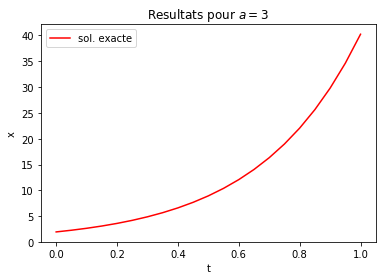

In [4]:
# votre code ci-dessous
x0=2.
T=1.
t0=0.
N=20
dt=T/N
TPS=np.linspace(0,T,N+1)
a=3.
X1exa=solexa(TPS, t0, x0)
plt.plot(TPS,X1exa, 'r',label='sol. exacte')
plt.legend()
plt.xlabel('t')
plt.ylabel('x')
plt.title('Resultats pour $a=3$')


Text(0.5, 1.0, 'Resultats pour $a=-2$')

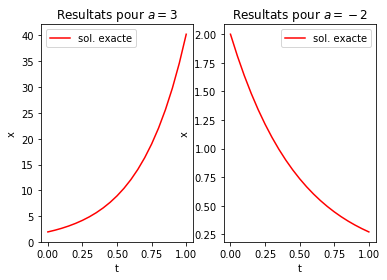

In [5]:
# le code modifié
x0=2.
T=1.
t0=0.
N=20
dt=T/N
TPS=np.linspace(0,T,N+1)
a=3.
X1exa=solexa(TPS, t0, x0)
a=-2.
X2exa=solexa(TPS, t0, x0)
plt.subplot(1,2,1)
plt.plot(TPS,X1exa, 'r',label='sol. exacte')
plt.legend()
plt.xlabel('t')
plt.ylabel('x')
plt.title('Resultats pour $a=3$')

plt.subplot(1,2,2)
plt.plot(TPS,X2exa, 'r',label='sol. exacte')
plt.legend()
plt.xlabel('t')
plt.ylabel('x')
plt.title('Resultats pour $a=-2$')



d) Compléter la  fonction $EulerExplicite$ ci dessous pour calculer une solution approchée par la méthode d'Euler explicite. La fonction renvoie le vecteur $X= (x_0,\ldots ,x_N)$ et $TPS= (t_0,\ldots ,t_N)$, où $t_N = T$ (que vaut $N$ en fonction de $T$ et de $dt$ ?). On utilisera la librairie $numpy$ pour créer et manipuler les vecteurs de réels $X$ et $TPS$.


In [6]:
def EulerExplicite(t0, x0, T, N, f):
# x0 et f(x0, t0) doivent etre des vecteurs lignes 
# renvoie TPS et X
# TPS est un vecteur ligne contenant les (N+1) temps intermediaires (t0, ..., tN)
# X a autant de colonnes que X0 et N+1 lignes; le résultat au temps ti est sur la ligne (i+1)
    if np.size(x0)==1: # on regarde si x0 est un reel
        # dans ce cas on le transforme en vecteur ligne de taille 1
        x0=np.array([float(x0)])
        
    # initialisation
    TPS=[t0] # TPS est un vecteur ligne
    X=[x0] #X est un tableau avec le même nombre de colonne que x0, et une ligne pour chaque t_i
    dt=T/N
    for i in range(N):
        # calcul de ma solution au temps suivant
        t1=t0+dt
        x1=x0+dt*f(x0,t0)
        
        # stockage des resultats
        TPS=np.append(TPS,[t1])
        #X=np.append(X,[x1])
        #TPS.append(t1)
        X.append(x1)
        # actualisation des valeurs 
        t0=t1
        x0=x1
        
    #print(type(X))
    return TPS, X



e) On prend $x_0 = 2$, $t_0 = 0$, $T = 1$,  $dt=0.05$ et $a=3$. Tracer sur un même graphe la solution exacte, la solution approchée avec la méthode d'Euler explicite, et la solution approchée obtenue avec scipy.intergrate.odeint (regarder l'aide d'utilisation de cette fonction). Ajouter à la figure un titre, des noms sur les axes, et une légende. Reprendre la question pour $a=-2$.

Text(0.5, 1.0, 'Resultats pour $a=-2$')

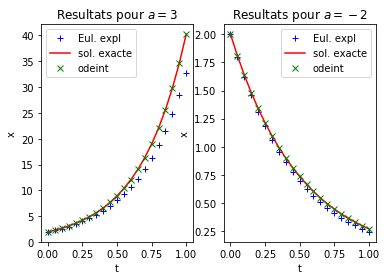

In [7]:
# votre code ci-dessous
x0=2.
T=1.
t0=0.
N=20

a=3.
[TPS, X1]=EulerExplicite(t0, x0, T, N, f)
RES1=odeint(f, x0, TPS)
X1exa=solexa(TPS, t0, x0)

a=-2.
[TPS, X2]=EulerExplicite(t0, x0, T, N, f)
RES2=odeint(f, x0, TPS)
X2exa=solexa(TPS, t0, x0)


plt.subplot(1,2,1)
plt.plot(TPS,X1, 'b+',TPS,X1exa, 'r', TPS,  RES1, 'gx')
plt.legend(['Eul. expl', 'sol. exacte', 'odeint'])
plt.xlabel('t')
plt.ylabel('x')
plt.title('Resultats pour $a=3$')

plt.subplot(1,2,2)
plt.plot(TPS,X2, 'b+',TPS,X2exa, 'r', TPS,  RES2, 'gx')
plt.legend(['Eul. expl', 'sol. exacte', 'odeint'])
plt.xlabel('t')
plt.ylabel('x')
plt.title('Resultats pour $a=-2$')



f) Etude qualitative : que se passe t-il quand on prend des pas de temps $dt$ de plus en plus petits ? On pourra par exemple écrire un programme qui affiche la solution exacte et les solutions obtenues par la méthode d'Euler explicite avec des couleurs différentes pour différentes valeurs de  $dt$. Comparer le comportement pour $a>0$ et $a<0$.

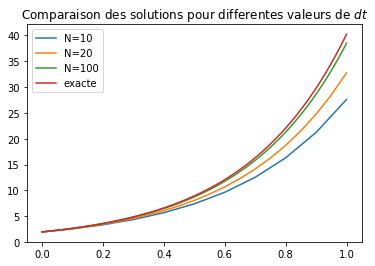

In [8]:
#votre code ci-dessous
a=3
#a=-3
#delta_t=[0.1,0.05,0.01]
N_=[10,20,100]
for N in N_:
    TPS,X=EulerExplicite(t0, x0, T, N, f)
    plt.plot(TPS,X, label="N={}".format(N))
    
Xexa=solexa(TPS, t0, x0)

plt.plot(TPS,Xexa, label="exacte")
plt.legend()
plt.title('Comparaison des solutions pour differentes valeurs de $dt$')
plt.show()

# 

Vos observations ici (cellule de type texte)

<cite><font color="red">Remarque </font></cite>: Quand on prend $dt$  plus petit, la solution approchée se rapproche
de la solution exacte. Numériquement, on constate que le schéma semble converger: quand
$dt$ tend vers 0, la courbe de la solution approchée «se colle» à la courbe de la solution exacte:
 $$ \displaystyle \max_{0 \leq j \leq N} ~ |\underbrace{x_{j}}_{\text{sol. approchée} \atop \text{ au temps } t_{j}}- \underbrace{x(t_{j})}_{\text{sol. exacte} \atop \text{ au temps } t_{j}}| \underset{\Delta t \rightarrow 0}{\longrightarrow} 0. $$
 
On observe que quand le pas de temps diminue, l'erreur diminue également, d'un facteur qui semble proportionnel (on verra cette observation dans la manip suivante) 

g) Etude quantitative 1 :  Ecrire une fonction "erreur" qui calcule $$E(N)=\max_{i=0,\ldots,N}|x(t_i)−x_i|,$$ où $x$ est la solution exacte et $x_i$ est l’approximation fournie par la méthode d’Euler au temps $t_i$ (que vaut $N$ en fonction de $T$ et de $dt$ ?).

Appliquer la fonction erreur à $N$ prenant les valeurs $10^i$ pour $i=1,\ldots,5$. Afficher  les quantités calculées.

Commenter les résultats.


In [9]:
#votre code ci-dessous

def erreur (t0, x0, T, N, f):    
    #calcul de la solution approchée
    TPS,X=EulerExplicite(t0, x0, T, N, f)
    #calcul de la solution exacte aux mêmes temps
    Xexa=(solexa(TPS,t0,x0))
    #calcul de l'erreur E
    c = [abs(X_elt - Xexa_elt) for X_elt, Xexa_elt in zip(X, Xexa)]
    E=max(c)
    return E

N_=[10,100,1000,10000,100000]
#ce premier print sert de titre de colonnes
print('erreur, N')

for N in N_:
    E=erreur(t0, x0, T, N, f)
    print(E, N)



erreur, N
[12.59937548] 10
[1.73380988] 100
[0.1800046] 1000
[0.0180693] 10000
[0.00180762] 100000


On observe que quand N est multiplié par 10, l'erreur est elle divisée par 10 (à peu près) 


h) Etude quantitative 2 : Tracer la courbe d’erreur en coordonnées logarithmiques en fonction de $dt$ pour les points suivants : 0.1, 0.01, 0.001, 0.0001, 0.00001. Superposer le graphe de la fonction f(dt)=dt. Commenter les résultats.

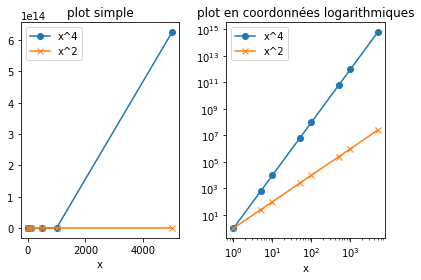

In [10]:
#exemple de graphique en échelle logarithmique
x=[1,5,10,50,100,500,1000,5000]
y=[xi**4 for xi in x]
z=[xi**2 for xi in x]
plt.subplot(1,2,1)
plt.plot(x,y,'-o')
plt.plot(x,z,'-x')
plt.legend(['x^4','x^2'],loc=2)
plt.title('plot simple')
plt.xlabel('x')
plt.subplot(1,2,2)
plt.plot(x,y,'-o')
plt.plot(x,z,'-x')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('x')
plt.legend(['x^4','x^2'],loc=2)
plt.title('plot en coordonnées logarithmiques')
plt.tight_layout()


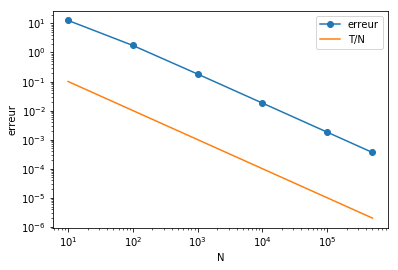

In [11]:
#votre code ci-dessous
N_=[10,100,1000,10000,100000,500000]
E_=[]
dt_=[]
for N in N_:
    E=erreur(t0, x0, T, N, f)
    E_.append(E)
    dt_.append(T/N)
plt.plot(N_,E_,'-o',N_,dt_,'-')
plt.xscale('log')
plt.yscale('log')
plt.legend(['erreur','T/N'])
plt.xlabel('N')
plt.ylabel('erreur')
plt.show()

<cite><font color="red">Remarques </font></cite>: 
1. On observe que le comportement de l'erreur au temps final en fonction du pas de temps est linéaire, puisqu'elle est parallèle à la droite de pente 1 (qui est le graphe de la fonction f(dt)=dt). 
2. On aurait pu voir ce comportement linéaire en coordonnées cartésiennes mais l'intérêt des coordonnées logarithmiques est qu'on distingue bien les différents pas de temps testés, même très petits.

# Exercice 2. 

Nous considérons l’équation différentielle d’ordre 2 suivante
$$\left\{\begin{array}{l}\ddot{x}(t) = -x(t),\\ x(0)=a_0\\ \dot x(0)=a_1\end{array}\right.$$
Nous testerons avec T = 5 et T = 4π.

a) Mettre l’équation proposée sous la forme d’un système différentiel d’ordre 1 d’inconnue $X=\begin{pmatrix} x\cr \dot x\end{pmatrix}$.

b) Quelle est la solution exacte de cette équation différentielle ? Ecrire une fonction $solexa2(t,a0,a1)$ renvoyant $x(t)$ et $\dot x(t)$. 


In [12]:
def solexa2(t,a0,a1):
    #votre code ci-dessous
    x=a0*np.cos(t)+a1*np.sin(t)
    xdot=-a0*np.sin(t)+a1*np.cos(t)
    return x,xdot


c) Ecrire une fonction $plotsol2(t,X)$ qui trace sur la même figure la position en fonction du temps dans le cadre de gauche, la vitesse en fonction du temps dans le cadre du milieu, et la vitesse en fonction de la position (espace des phases) dans le cadre de droite. $t$ contient les temps discrétisés, $X$ contient les vecteurs (position,vitesse) correspondants.


In [13]:
def plotsol2(t,X):
    #votre code ci-dessous
    # on commence par creer deux listes positions vitesses
    pos=X[0]
    vit=X[1]

    plt.figure(figsize=(10,5))
    plt.subplot(2,2,1)  # le graphe de la position en fonction du temps
    plt.plot(t,pos,label='sol exacte')
    plt.xlabel('temps')
    plt.ylabel('position')
    plt.title('Position en fonction du temps')
    
    plt.subplot(2,2,2) # le graphe de la vitesse en fonction du temps
    plt.plot(t,vit,label='sol exacte')
    plt.xlabel('temps')
    plt.ylabel('vitesse')
    plt.title('Vitesse en fonction du temps')


    plt.subplot(2,2,3) #le graphe dans l'espace des phases
    plt.plot(pos, vit,label='sol exacte')
    plt.xlabel('position')
    plt.ylabel('vitesse')
    plt.title('Espace des phases')
    # Place a legend to the right of this smaller subplot.
    plt.legend(bbox_to_anchor=(1.2, 0.8), loc='upper left', borderaxespad=0.)
    plt.tight_layout()


d)  Tester la fonction plotsol2 sur la solution exacte pour  $a_0 = 1$, $a_1 = 1$, $T = 4 \pi$,  et $dt=0.05$ 

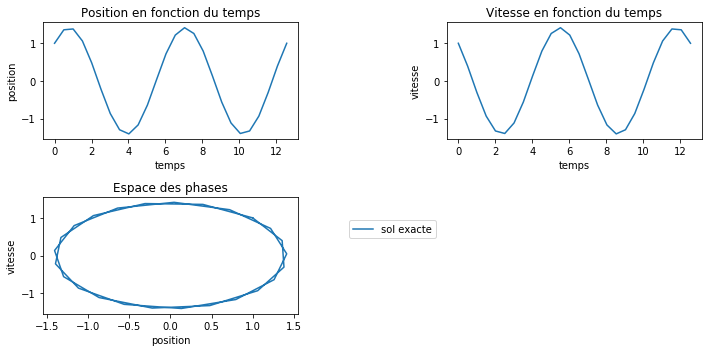

In [14]:
#votre code ci-dessous

a0=1.
a1=1.
T=4*np.pi
dt=0.5
N=int(T/dt)
t=np.linspace(0,T,N+1)
X=solexa2(t,a0,a1)
# X est une liste qui contient deux éléments: le premier est le premier résultat de solexa2,
# le second est le second résultat de solexa2
plotsol2(t,X)



e) Programmer la fonction second membre $f2(x,t)$ pour cet exemple, puis calculer la solution approchée de ce problème avec la méthode d'Euler. Attention maintenant $f2$ est une fonction vectorielle à deux composantes. Ainsi $f2(x,t)$ est  une liste de deux  termes. 

In [15]:
def f2(X,t):
# attention a l'ordre des arguments, impose par le solveur python scipy.integrate.odeint
# X est un vecteur ligne
    Y=np.asarray([X[1], -X[0]]) #la commande np.asarray force python à comprendre que Y est un tableau numpy

    return Y


f) Tracer sur le même graphique à 3 fenetres (position par rapport au temps, vitesse par rapport au temps, et graphe dans l'espace des phases) la solution exacte et celle calculée avec Euler explicite. Utiliser des couleurs différentes et mettre une légende. On pourra s'inspirer de la fonction plotsol2. Attention le tableau python contenant la solution numérique n'a pas forcément la même structure que celui de la solution exacte



In [16]:
def plotsol2_2(t,X_exacte,X_EE):
    #votre code ci-dessous
    # on commence par creer deux listes positions vitesses
    pos=X_exacte[0]
    vit=X_exacte[1]
    
    plt.subplot(2,2,1)  # le graphe de la position en fonction du temps
    plt.plot(t,pos,label='sol exacte')
    plt.xlabel('temps')
    plt.ylabel('position')
    plt.title('Position en fonction du temps')
    
    plt.subplot(2,2,2) # le graphe de la vitesse en fonction du temps
    plt.plot(t,vit,label='sol exacte')
    plt.xlabel('temps')
    plt.ylabel('vitesse')
    plt.title('Vitesse en fonction du temps')


    plt.subplot(2,2,3) #le graphe dans l'espace des phases
    plt.plot(pos, vit,label='sol exacte')
    plt.xlabel('position')
    plt.ylabel('vitesse')
    plt.title('Espace des phases')
    
    pos=[x[0] for x in X_EE]
    vit=[x[1] for x in X_EE]
    plt.subplot(2,2,1)  # le graphe de la position en fonction du temps
    plt.plot(t,pos,label='Euler explicite')
    plt.subplot(2,2,2) # le graphe de la vitesse en fonction du temps
    plt.plot(t,vit,label='Euler explicite')
    plt.subplot(2,2,3) #le graphe dans l'espace des phases
    plt.plot(pos, vit,label='Euler explicite')
    
    # Place a legend to the right of this smaller subplot.
    plt.legend(bbox_to_anchor=(1.2, 0.8), loc='upper left', borderaxespad=0.)
    plt.tight_layout()


In [17]:

a0=1.
a1=1.
T=4*np.pi
X2=np.array([a0,a1])
print ("size(X2)",size(X2),"np.size(X2)",np.size(X2))
dt=0.5
N=int(T/dt)
TPS, XEE=EulerExplicite(t0, X2, T, N, f2)
#print ('XEE',XEE)
print(size(XEE),XEE[0])
plotsol2_2(t,X,XEE)

NameError: name 'size' is not defined

g) Calculer une autre solution numérique avec le schéma d'Euler modifié obtenu en utilisation la formule du point milieu
$$y_{n+1}=y_n+hf\left(t_n+\frac{h}{2},y_n+\frac{h}{2}f(t_n,y_n)\right)$$

In [ ]:
def EulerModifie(t0, x0, T, N, f):
# x0 et f(x0, t0) doivent etre des vecteurs lignes 
# renvoie TPS et X
# TPS est un vecteur ligne contenant les (N+1) temps intermediaires (t0, ..., tN)
# X a autant de colonnes que X0 et N+1 lignes; le résultat au temps ti est sur la ligne (i+1)
    if np.size(x0)==1: # on regarde si x0 est un reel
        # dans ce cas on le transforme en vecteur ligne de taille 1
        x0=np.array([float(x0)])
        
    # initialisation
    TPS=[t0] # TPS est un vecteur ligne
    X=[x0] #X est un tableau avec le même nombre de colonne que x0, et une ligne pour chaque t_i
    dt=T/N
    for i in range(N):
        # calcul de ma solution au temps suivant
        x1=x0+dt*f(x0,t0)/2
        x0=x0+dt*f(x1,t0+dt/2)
        # stockage des resultats
        #X=np.append(X,[x1])
        #TPS.append(t1)
        X.append(x0)
        # actualisation des valeurs 
        t0=t0+dt
        TPS=np.append(TPS,[t0])
        
    #print(type(X))
    return TPS, X



Pour éviter de répéter plusieurs fois les mêmes lignes de code on 
réorganise la fonction plotsol

In [ ]:
def plotsol(t,pos,vit,etiquette):
    plt.subplot(2,2,1)  # le graphe de la position en fonction du temps
    plt.plot(t,pos,label=etiquette)
    plt.subplot(2,2,2) # le graphe de la vitesse en fonction du temps
    plt.plot(t,vit,label=etiquette)
    plt.subplot(2,2,3) #le graphe dans l'espace des phases
    plt.plot(pos, vit,label=etiquette)
    
def plotsol2_3(t,X_exacte,X_EE,X_EM):
    #votre code ci-dessous
    # on commence par creer deux listes positions vitesses
    plt.subplot(2,2,1)  # le graphe de la position en fonction du temps
    plt.xlabel('temps')
    plt.ylabel('position')
    plt.title('Position en fonction du temps')
    
    plt.subplot(2,2,2) # le graphe de la vitesse en fonction du temps
    plt.xlabel('temps')
    plt.ylabel('vitesse')
    plt.title('Vitesse en fonction du temps')


    plt.subplot(2,2,3) #le graphe dans l'espace des phases
    plt.xlabel('position')
    plt.ylabel('vitesse')
    plt.title('Espace des phases')
    
    pos=X_exacte[0]
    vit=X_exacte[1]
    plotsol(t,pos,vit,'sol exacte')
    pos=[x[0] for x in X_EE]
    vit=[x[1] for x in X_EE]
    plotsol(t,pos,vit,'Euler explicite')
    pos=[x[0] for x in X_EM]
    vit=[x[1] for x in X_EM]
    plotsol(t,pos,vit,'Euler modifié')
    
    # Place a legend to the right of this smaller subplot.
    plt.legend(bbox_to_anchor=(1.2, 0.8), loc='upper left', borderaxespad=0.)
    plt.tight_layout()


In [ ]:
a0=1.
a1=1.
T=4*np.pi
X2=np.array([a0,a1])
print ("size(X2)",size(X2),"np.size(X2)",np.size(X2))
dt=0.5
N=int(T/dt)
TPS, XEM=EulerModifie(t0, X2, T, N, f2)
plotsol2_3(t,X,XEE,XEM)

On remarque que le schéma d'Euler modifié est plus précis que le schéma d'Euler explicite puisqu'avec la même discrétisation on obtient une solution beaucoup plus proche de la soltuyion exacte.

h) Calculer une  solution approchée avec le solveur $scipy.integrate.odeint$. Afficher avec les trois solutions précédentes. Là encore on fera attention à la structure de la solution renvoyée par odeint

In [ ]:
def plotsol2_4(t,X_exacte,X_EE,X_EM,X_odeint):
    #votre code ci-dessous
    # on commence par creer deux listes positions vitesses
    plt.subplot(2,2,1)  # le graphe de la position en fonction du temps
    plt.xlabel('temps')
    plt.ylabel('position')
    plt.title('Position en fonction du temps')
    
    plt.subplot(2,2,2) # le graphe de la vitesse en fonction du temps
    plt.xlabel('temps')
    plt.ylabel('vitesse')
    plt.title('Vitesse en fonction du temps')


    plt.subplot(2,2,3) #le graphe dans l'espace des phases
    plt.xlabel('position')
    plt.ylabel('vitesse')
    plt.title('Espace des phases')
    
    pos=X_exacte[0]
    vit=X_exacte[1]
    plotsol(t,pos,vit,'sol exacte')
    pos=[x[0] for x in X_EE]
    vit=[x[1] for x in X_EE]
    plotsol(t,pos,vit,'Euler explicite')
    pos=[x[0] for x in X_EM]
    vit=[x[1] for x in X_EM]
    plotsol(t,pos,vit,'Euler modifié')
    pos=X_odeint[:,0]
    vit=X_odeint[:,1]
    plotsol(t,pos,vit,'odeint')

    # Place a legend to the right of this smaller subplot.
    plt.legend(bbox_to_anchor=(1.2, 0.8), loc='upper left', borderaxespad=0.)
    plt.tight_layout()


In [ ]:
Xexa=solexa2(TPS,a0,a1)
RES=odeint(f2, X2, TPS)
plotsol2_4(t,X,XEE,XEM,RES)



h) Sur le graphique dans l'espace des phases, tracer à l’aide de la fonction $matplotlib.pyplot.quiver$ la dynamique du problème i.e le champ de vecteur associé à $f$.

In [ ]:
#exemple d'utilisation de quiver
import matplotlib.pyplot as plt
import numpy as np
from numpy import ma

figure(figsize=(20,10))

X, Y = np.meshgrid(np.arange(0, 2 * np.pi, .2), np.arange(0, 2 * np.pi, .2))
U = np.cos(X)
V = np.sin(Y)
# Normalisation des vecteurs
N=np.hypot(U,V) 
Unorm=U/N
Vnorm=V/N
plt.subplot(1,2,1)
# Le dernier paramètre permet de colorier en fonction de la norme
Q = plt.quiver(X, Y, Unorm, Vnorm, N)
plt.title('Champ de vecteurs normes et colories en fonction de la norme')
plt.subplot(1,2,2)
Q2 = plt.quiver(X, Y, U, V)
plt.title('Champ de vecteur non normes')
plt.legend()
plt.show()

In [ ]:
figure(figsize=(10,10))

#############################
# Mise en place de la grille 
############################

y1 = np.linspace(-2., 2., 30)
y2 = np.linspace(-2., 2., 30)

Y1, Y2 = np.meshgrid(y1, y2)

#####################
# Champ de vecteurs
####################

#Initialisation des vecteurs
U, V = np.zeros(Y1.shape), np.zeros(Y2.shape)
NI, NJ = Y1.shape

#Calcul 
for i in range(NI):
    for j in range(NJ):
        x = Y1[i, j]
        y = Y2[i, j]
        U[i,j] = f2([x, y], t)[0]
        V[i,j] = f2([x, y], t)[1]

#Normalisation des vecteurs
N=np.hypot(U,V)
U/=N
V/=N

#Traçons
plt.quiver(Y1, Y2, U, V, N)

####################
# Portrait de phase
####################

l=[0.1,1,1.5]   # pour en dessiner plusieurs 
a0=1
TPS= np.linspace(0, 50, 300)
for a1 in l:
    X2=np.array([a0,a1])
    RES=odeint(f2, X2, TPS)
    posRES=RES[:,0]
    vitRES=RES[:,1]
    plt.plot(posRES,vitRES,'b')
    
plt.ylim([-2,2])
plt.xlim([-2,2])    
plt.legend(['Portrait de phase'],loc=1)
plt.title('Portrait de phase et champ de vecteurs')


plt.show()
